# Tutorial 1: Pengumpulan Data dengan YouTube Data API v3

Notebook ini digunakan untuk mendemonstrasikan proses pengumpulan data melalui YouTube Data API v3. Jalankan setiap cell secara berurutan agar variabel dan fungsi yang dibutuhkan sudah tersedia saat digunakan. Credential dibaca dari environment variable atau file `.env`, sehingga nilainya tidak perlu dan tidak boleh ditulis langsung di notebook.

Tutorial ini menggunakan API key YouTube untuk mengambil data publik. API key dibuat melalui Google Cloud Console. Sementara itu, operasi seperti membuat, mengubah, atau menghapus data memerlukan OAuth dan tidak dibahas dalam tutorial ini.

Fokus tutorial adalah memahami alur kerja API dari awal sampai data siap disimpan: menyiapkan credential, mengirim request, membandingkan hasil pencarian, membaca response JSON, melakukan pagination, mengubah data menjadi `DataFrame`, dan menyimpan hasil. Beberapa bagian tambahan menunjukkan fitur API yang berguna untuk eksplorasi lebih lanjut.


## 0. Setup dan Import Library

Bagian ini menyiapkan library dan konfigurasi dasar yang akan dipakai sepanjang tutorial. `requests` digunakan untuk mengirim HTTP request ke API, `pandas` untuk mengolah data tabular, `python-dotenv` untuk membaca credential dari file `.env`, dan `matplotlib` untuk visualisasi sederhana. Folder `data/` juga dibuat otomatis untuk menyimpan hasil pengumpulan data.

Jika library belum tersedia pada environment yang digunakan, jalankan baris instalasi terlebih dahulu.

In [46]:
# Jalankan hanya jika package belum tersedia.
# %pip install requests pandas python-dotenv matplotlib

from datetime import datetime, timezone
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import requests
from dotenv import load_dotenv
from IPython.display import display

load_dotenv()

DATA_DIRECTORY = Path("data")
DATA_DIRECTORY.mkdir(exist_ok=True)
REQUEST_TIMEOUT_SECONDS = 30

print("Import library dan konfigurasi awal selesai.")

Import library dan konfigurasi awal selesai.


Bagian berikut mendefinisikan helper function yang dipakai berulang kali sepanjang notebook. Helper ini menangani pembacaan environment variable, timestamp UTC, penyimpanan `DataFrame`, validasi kolom identifier, dan pencatatan metadata. Dengan memusatkan fungsi-fungsi umum di satu tempat, bagian berikutnya dapat lebih fokus pada logika API.

In [47]:
def require_environment_variable(variable_name: str) -> str:
    """Mengambil environment variable yang wajib tersedia tanpa menampilkan nilainya."""
    value = os.getenv(variable_name)

    if not value:
        raise RuntimeError(f"Atur {variable_name} pada environment atau file .env sebelum menjalankan cell ini.")

    return value


def utc_timestamp() -> str:
    """Mengembalikan waktu pengumpulan data saat ini dalam format ISO 8601 UTC."""
    return datetime.now(timezone.utc).isoformat()


def save_dataframe(dataframe: pd.DataFrame, filename: str) -> Path:
    """Menyimpan DataFrame sebagai file CSV UTF-8 dan mengembalikan path file hasilnya."""
    output_path = DATA_DIRECTORY / filename
    dataframe.to_csv(output_path, index=False, encoding="utf-8")
    return output_path


def validate_identifier_column(dataframe: pd.DataFrame, column_name: str) -> None:
    """Memvalidasi kolom ID dan menghentikan proses jika kolom hilang, kosong, atau duplikat."""
    if column_name not in dataframe.columns:
        raise ValueError(f"Kolom {column_name} tidak ditemukan.")

    if dataframe[column_name].isna().any() or (dataframe[column_name] == "").any():
        raise ValueError(f"Kolom {column_name} memiliki nilai kosong.")

    if dataframe[column_name].duplicated().any():
        raise ValueError(f"Kolom {column_name} memiliki ID duplikat.")


def write_collection_metadata(metadata: dict) -> Path:
    """Menyimpan metadata pengumpulan data ke JSON tanpa menyertakan credential."""
    output_path = DATA_DIRECTORY / "collection_metadata.json"
    output_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")
    return output_path


# Metadata dibuat sejak awal agar seluruh proses pengumpulan dapat dicatat secara konsisten.
collection_metadata = {"python_version": sys.version}

Alur utama tutorial ini mencakup pencarian dengan dua kata kunci, pembentukan tabel, pagination, detail video dan channel, komentar, penyimpanan, serta visualisasi. Bagian setelahnya membahas endpoint dan fitur request lanjutan.


## 1. Memuat YouTube API Key

Sebelum mengirim request ke YouTube Data API, API key harus sudah tersedia pada environment. Simpan key sebagai `YT_API_KEY` di file `.env`, environment variable, atau Colab Secrets. Bagian ini hanya membaca dan memeriksa ketersediaannya; nilai key tidak pernah ditampilkan ke output notebook.

In [48]:
YT_API_KEY = require_environment_variable("YT_API_KEY")
YOUTUBE_API_BASE_URL = "https://www.googleapis.com/youtube/v3"

print("YouTube API key berhasil dimuat.")

YouTube API key berhasil dimuat.


Agar pola request tidak perlu ditulis ulang pada setiap bagian, seluruh request baca ke YouTube dilewatkan melalui helper `youtube_get()`. Fungsi ini menerima nama resource dan parameter, menambahkan API key secara otomatis, lalu mengembalikan response dalam bentuk JSON.

Bentuk URL yang digunakan adalah: `https://www.googleapis.com/youtube/v3/{resource}?{parameter}&key={API key}`

Bagian `{resource}` menunjukkan endpoint yang dituju, misalnya `search`, `videos`, atau `channels`. API key dikirim sebagai query parameter. Helper kedua, `extract_youtube_error()`, digunakan untuk mengambil alasan error yang paling relevan dari body response agar pesan error lebih mudah dibaca dan dicatat.

In [49]:
def youtube_get(resource: str, parameters: dict) -> dict:
    """Mengirim request GET ke satu resource YouTube dan mengembalikan response JSON."""
    response = requests.get(
        f"{YOUTUBE_API_BASE_URL}/{resource}",
        params={**parameters, "key": YT_API_KEY},
        timeout=REQUEST_TIMEOUT_SECONDS,
    )
    response.raise_for_status()
    return response.json()


def extract_youtube_error(error: requests.HTTPError) -> str:
    """Mengambil alasan error YouTube yang ringkas agar mudah dicatat pada metadata."""
    try:
        error_payload = error.response.json()
        reasons = error_payload.get("error", {}).get("errors", [])

        if reasons:
            return reasons[0].get("reason", error_payload["error"].get("message", "unknown_error"))
    except ValueError:
        pass

    return str(error)

## 2. Memahami Kuota YouTube

Setiap request ke YouTube Data API menggunakan kuota, termasuk request yang gagal karena parameter tidak valid. Biaya kuota tiap method berbeda: `search.list` relatif lebih mahal dibanding request metadata seperti `videos.list` atau `channels.list`.

Saat demonstrasi, gunakan `maxResults` secukupnya dan gabungkan beberapa ID dalam satu request jika endpoint mendukung batch. Tujuannya bukan hanya menghemat kuota, tetapi juga membiasakan pola pengambilan data yang efisien.

## 3. Mencari Video dengan `search.list`

Langkah pertama adalah mencari video berdasarkan kata kunci menggunakan endpoint `search.list`. Pada contoh ini, kita membandingkan query `"artificial intelligence"` dan `"kecerdasan buatan"` agar terlihat bahwa pilihan kata kunci dapat menghasilkan sampel yang berbeda. Hasil query pertama digunakan sebagai data utama pada langkah berikutnya.

Empat parameter utama yang digunakan:
- `q` adalah kata kunci pencarian.
- `part=snippet` menentukan kelompok property yang diminta. Satu resource YouTube dibagi ke beberapa bagian, dan `snippet` berisi metadata dasar seperti judul, nama channel, dan waktu publikasi. Meminta bagian yang tidak dipakai hanya memperbesar response.
- `type=video` membatasi hasil hanya ke video, sehingga setiap item dijamin punya `videoId`.
- `maxResults` mengatur jumlah item per halaman, maksimal 50.

`search.list` hanya mengembalikan metadata ringkas. Statistik seperti jumlah view, like, dan komentar akan diambil melalui `videos.list`.


In [50]:
YOUTUBE_QUERIES = ["artificial intelligence", "kecerdasan buatan"]
YOUTUBE_MAX_RESULTS = 10

youtube_search_responses = {}
video_ids_per_query = {}

# Jalankan pencarian untuk setiap query dan simpan masing-masing response.
for query in YOUTUBE_QUERIES:
    search_parameters = {
        "part": "snippet",
        "q": query,
        "type": "video",
        "maxResults": YOUTUBE_MAX_RESULTS,
    }
    response = youtube_get("search", search_parameters)
    youtube_search_responses[query] = response

    video_ids = set()
    for item in response.get("items", []):
        video_id = item.get("id", {}).get("videoId")
        if video_id:
            video_ids.add(video_id)
    video_ids_per_query[query] = video_ids

    print(f"{query!r}: {len(response.get('items', []))} hasil")


# Gunakan query pertama hanya sebagai contoh untuk melihat struktur response.
# Tidak ada request API baru pada bagian ini karena response sudah disimpan sebelumnya.
YOUTUBE_QUERY = YOUTUBE_QUERIES[0]
youtube_search_response = youtube_search_responses[YOUTUBE_QUERY]

print(f"Contoh raw response search.list untuk {YOUTUBE_QUERY!r} (item pertama):")
print(json.dumps(youtube_search_response["items"][0], indent=2, ensure_ascii=False))

overlap = set.intersection(*(video_ids_per_query[query] for query in YOUTUBE_QUERIES))
unique_video_ids = set.union(*(video_ids_per_query[query] for query in YOUTUBE_QUERIES))

print(f"\nJumlah video unik dari seluruh pencarian: {len(unique_video_ids)}")
print(f"Video yang muncul di kedua pencarian: {len(overlap)}")

print(f"\nSeluruh hasil pencarian untuk {YOUTUBE_QUERY!r}:")
display(pd.json_normalize(youtube_search_response.get("items", [])))

'artificial intelligence': 10 hasil
'kecerdasan buatan': 10 hasil
Contoh raw response search.list untuk 'artificial intelligence' (item pertama):
{
  "kind": "youtube#searchResult",
  "etag": "kh-vFIj_XxmQbgqP5-NolcnaxW8",
  "id": {
    "kind": "youtube#video",
    "videoId": "btpRfPC3Yhw"
  },
  "snippet": {
    "publishedAt": "2026-09-07T17:20:06Z",
    "channelId": "UCZFMm1mMw0F81Z37aaEzTUA",
    "title": "Artificial Intelligence | AI&#39;s Alien Mind: Can Humans Still Stay In Control?",
    "description": "OpenAI's Chief Scientist has sounded the alarm on the future of artificial intelligence. As AI systems begin solving problems in ...",
    "thumbnails": {
      "default": {
        "url": "https://i.ytimg.com/vi/btpRfPC3Yhw/default.jpg",
        "width": 120,
        "height": 90
      },
      "medium": {
        "url": "https://i.ytimg.com/vi/btpRfPC3Yhw/mqdefault.jpg",
        "width": 320,
        "height": 180
      },
      "high": {
        "url": "https://i.ytimg.com/vi/

,kind,etag,id.kind,id.videoId,snippet.publishedAt,snippet.channelId,snippet.title,snippet.description,snippet.thumbnails.default.url,snippet.thumbnails.default.width,snippet.thumbnails.default.height,snippet.thumbnails.medium.url,snippet.thumbnails.medium.width,snippet.thumbnails.medium.height,snippet.thumbnails.high.url,snippet.thumbnails.high.width,snippet.thumbnails.high.height,snippet.channelTitle,snippet.liveBroadcastContent,snippet.publishTime
0,youtube#searchResult,kh-vFIj_XxmQbgqP5-NolcnaxW8,youtube#video,btpRfPC3Yhw,2026-09-07T17:20:06Z,UCZFMm1mMw0F81Z37aaEzTUA,Artificial Intelligence | AI&#39;s Alien Mind:...,OpenAI's Chief Scientist has sounded the alarm...,https://i.ytimg.com/vi/btpRfPC3Yhw/default.jpg,120,90,https://i.ytimg.com/vi/btpRfPC3Yhw/mqdefault.jpg,320,180,https://i.ytimg.com/vi/btpRfPC3Yhw/hqdefault.jpg,480,360,NDTV,none,2026-09-07T17:20:06Z
1,youtube#searchResult,vWLgXgtPN-Wm-c9xOAChY5rEnkw,youtube#video,_19pRsZRiz4,2013-05-22T03:40:33Z,UCeR7qki1ikig6q4HwvP6dTg,A.I. Artificial Intelligence - Official® Trail...,"Release Date: June 29, 2001 It's the mid-21st ...",https://i.ytimg.com/vi/_19pRsZRiz4/default.jpg,120,90,https://i.ytimg.com/vi/_19pRsZRiz4/mqdefault.jpg,320,180,https://i.ytimg.com/vi/_19pRsZRiz4/hqdefault.jpg,480,360,TrailersPlaygroundHD,none,2013-05-22T03:40:33Z
2,youtube#searchResult,0BXtzD_Afc2J8gkhp4UORIz4ScE,youtube#video,ad79nYk2keg,2019-04-30T14:30:01Z,UCsvqVGtbbyHaMoevxPAq9Fg,What Is AI? | Artificial Intelligence | What i...,""" Michigan Engineering Professional Certifica...",https://i.ytimg.com/vi/ad79nYk2keg/default.jpg,120,90,https://i.ytimg.com/vi/ad79nYk2keg/mqdefault.jpg,320,180,https://i.ytimg.com/vi/ad79nYk2keg/hqdefault.jpg,480,360,Simplilearn,none,2019-04-30T14:30:01Z
3,youtube#searchResult,6WEQkzud-Xf6Q_sIPHWGBKbprjk,youtube#video,v5skA_fUrQ4,2025-12-18T09:01:25Z,UCUYgCukQfUN2DImPYrBiV4g,Sejarah Lengkap Perkembangan Artificial Intell...,Daftar di sini: https://go.dbs.com/dbsfcodingc...,https://i.ytimg.com/vi/v5skA_fUrQ4/default.jpg,120,90,https://i.ytimg.com/vi/v5skA_fUrQ4/mqdefault.jpg,320,180,https://i.ytimg.com/vi/v5skA_fUrQ4/hqdefault.jpg,480,360,Fajrul Fx,none,2025-12-18T09:01:25Z
4,youtube#searchResult,Sg_xWMoPf604HGfmEY5l-L3wk4s,youtube#video,F-pMp8AaXvw,2025-05-25T18:09:46Z,UC-7XpwWJcpBT0l_odHXljfA,artificial intelligence(SLOWED),,https://i.ytimg.com/vi/F-pMp8AaXvw/default.jpg,120,90,https://i.ytimg.com/vi/F-pMp8AaXvw/mqdefault.jpg,320,180,https://i.ytimg.com/vi/F-pMp8AaXvw/hqdefault.jpg,480,360,JG,none,2025-05-25T18:09:46Z
5,youtube#searchResult,3rvcyz60P-hTUsntAg9-94Oyeus,youtube#video,Yq0QkCxoTHM,2023-11-14T13:00:33Z,UCwAnu01qlnVg1Ai2AbtTMaA,Google’s AI Course for Beginners (in 10 minutes)!,Grab my AI Toolkit for free: https://academy.j...,https://i.ytimg.com/vi/Yq0QkCxoTHM/default.jpg,120,90,https://i.ytimg.com/vi/Yq0QkCxoTHM/mqdefault.jpg,320,180,https://i.ytimg.com/vi/Yq0QkCxoTHM/hqdefault.jpg,480,360,Jeff Su,none,2023-11-14T13:00:33Z
6,youtube#searchResult,Oa_sVevccBPpIXZvSqetoiR0o0c,youtube#video,uMzUB89uSxU,2022-12-14T14:46:25Z,UCsvqVGtbbyHaMoevxPAq9Fg,What is Artificial Intelligence? | Artificial ...,""" Michigan Engineering Professional Certifica...",https://i.ytimg.com/vi/uMzUB89uSxU/default.jpg,120,90,https://i.ytimg.com/vi/uMzUB89uSxU/mqdefault.jpg,320,180,https://i.ytimg.com/vi/uMzUB89uSxU/hqdefault.jpg,480,360,Simplilearn,none,2022-12-14T14:46:25Z
7,youtube#searchResult,mTwDlPKmpiT2We_kGrZOKXsniVc,youtube#video,qYNweeDHiyU,2024-08-05T11:00:52Z,UCKWaEZ-_VweaEx1j62do_vQ,"AI, Machine Learning, Deep Learning and Genera...",Want to learn more about Agentic AI + Data? Re...,https://i.ytimg.com/vi/qYNweeDHiyU/default.jpg,120,90,https://i.ytimg.com/vi/qYNweeDHiyU/mqdefault.jpg,320,180,https://i.ytimg.com/vi/qYNweeDHiyU/hqdefault.jpg,480,360,IBM Technology,none,2024-08-05T11:00:52Z
8,youtube#searchResult,YTCLsonVj_YEYJhryjp0gS1r82Q,youtube#video,m8o2GrbR3d8,2025-07-09T15:37:04Z,UChbpF5QVaVr9KUJT40qhKAg,SIMPLEST Explanation of How Artificial Intelli...,What is AI

## 4. Mengubah Hasil Pencarian menjadi `DataFrame`

Response dari API berbentuk JSON bertingkat, sedangkan proses analisis dan validasi akan lebih mudah jika datanya sudah berbentuk tabel. Bagian berikut mengekstrak field yang dibutuhkan dari setiap item, lalu menyusunnya menjadi `DataFrame`.

Walaupun request sebelumnya menggunakan `type=video`, kode tetap memeriksa keberadaan `videoId`. Item tanpa `videoId` akan dilewati agar fungsi lebih aman jika suatu saat dipakai pada response dengan konfigurasi berbeda.

In [51]:
def youtube_search_dataframe(search_response: dict) -> pd.DataFrame:
    """Mengubah item hasil pencarian yang memiliki videoId menjadi DataFrame."""
    rows = []

    # Ambil hanya hasil bertipe video dan ekstrak metadata yang relevan.
    for item in search_response.get("items", []):
        video_id = item.get("id", {}).get("videoId")

        # Lewati item yang tidak memiliki videoId.
        if not video_id:
            continue

        snippet = item.get("snippet", {})

        rows.append({
            "video_id": video_id,
            "title": snippet.get("title"),
            "channel_id": snippet.get("channelId"),
            "channel_title": snippet.get("channelTitle"),
            "published_at": snippet.get("publishedAt"),
        })

    return pd.DataFrame(rows)


# Konversi response dari contoh query sebelumnya ke bentuk tabular.
df_youtube_search = youtube_search_dataframe(youtube_search_response)

# Pastikan setiap baris memiliki video_id yang valid sebelum digunakan lebih lanjut.
validate_identifier_column(df_youtube_search, "video_id")

display(df_youtube_search)

,video_id,title,channel_id,channel_title,published_at
0,btpRfPC3Yhw,Artificial Intelligence | AI&#39;s Alien Mind:...,UCZFMm1mMw0F81Z37aaEzTUA,NDTV,2026-09-07T17:20:06Z
1,_19pRsZRiz4,A.I. Artificial Intelligence - Official® Trail...,UCeR7qki1ikig6q4HwvP6dTg,TrailersPlaygroundHD,2013-05-22T03:40:33Z
2,ad79nYk2keg,What Is AI? | Artificial Intelligence | What i...,UCsvqVGtbbyHaMoevxPAq9Fg,Simplilearn,2019-04-30T14:30:01Z
3,v5skA_fUrQ4,Sejarah Lengkap Perkembangan Artificial Intell...,UCUYgCukQfUN2DImPYrBiV4g,Fajrul Fx,2025-12-18T09:01:25Z
4,F-pMp8AaXvw,artificial intelligence(SLOWED),UC-7XpwWJcpBT0l_odHXljfA,JG,2025-05-25T18:09:46Z
5,Yq0QkCxoTHM,Google’s AI Course for Beginners (in 10 minutes)!,UCwAnu01qlnVg1Ai2AbtTMaA,Jeff Su,2023-11-14T13:00:33Z
6,uMzUB89uSxU,What is Artificial Intelligence? | Artificial ...,UCsvqVGtbbyHaMoevxPAq9Fg,Simplilearn,2022-12-14T14:46:25Z
7,qYNweeDHiyU,"AI, Machine Learning, Deep Learning and Genera...",UCKWaEZ-_VweaEx1j62do_vQ,IBM Technology,2024-08-05T11:00:52Z
8,m8o2GrbR3d8,SIMPLEST Explanation of How Artificial Intelli...,UChbpF5QVaVr9KUJT40qhKAg,Science Simplified 4 All,2025-07-09T15:37:04Z
9,JMLsHI8aV0g,How China Is Using Artificial Intelligence in ...,UCK7tptUDHh-RYDsdxO1-5QQ,The Wall Street Journal,2019-10-01T17:20:56Z


## 5. Demonstrasi Pagination

Satu request tidak selalu mengembalikan seluruh hasil. Jika masih ada halaman berikutnya, YouTube menyertakan `nextPageToken` pada response. Token tersebut dapat dikirim kembali sebagai `pageToken` untuk mengambil halaman berikutnya.

Agar demonstrasi tidak menggunakan kuota tambahan secara otomatis, bagian ini hanya mengecek apakah token tersedia. Ubah `FETCH_SECOND_YOUTUBE_PAGE` menjadi `True` jika ingin benar-benar mengambil halaman kedua.

In [52]:
FETCH_SECOND_YOUTUBE_PAGE = False

# Ambil token halaman berikutnya dari response pencarian sebelumnya.
next_page_token = youtube_search_response.get("nextPageToken")

print("Apakah nextPageToken tersedia?", bool(next_page_token))

# Request halaman kedua hanya dijalankan jika diaktifkan dan token tersedia.
if FETCH_SECOND_YOUTUBE_PAGE and next_page_token:
    second_page_parameters = {
        "part": "snippet",
        "q": YOUTUBE_QUERY,
        "type": "video",
        "maxResults": YOUTUBE_MAX_RESULTS,
        "pageToken": next_page_token,
    }

    # Gunakan parameter pencarian yang sama dengan tambahan pageToken.
    second_page_response = youtube_get(
        "search",
        second_page_parameters,
    )

    # Konversi hasil halaman kedua ke DataFrame agar lebih mudah diperiksa.
    df_youtube_search_page_2 = youtube_search_dataframe(second_page_response)

    display(df_youtube_search_page_2)

Apakah nextPageToken tersedia? True


## 6. Mengambil Detail dan Statistik Video


Hasil pencarian sebelumnya belum memuat statistik video. Untuk mengambil jumlah view, like, dan komentar, kita menggunakan `videos.list`.

Endpoint ini menerima hingga 50 video ID dalam satu request. Karena itu, fungsi `chunks()` membagi daftar ID ke dalam batch maksimal 50 agar pengambilan data tetap efisien.

Kolom statistik dikonversi ke tipe `Int64` milik pandas. Berbeda dengan `int64` biasa, tipe ini dapat menyimpan `pd.NA`. Hal ini penting karena beberapa statistik memang bisa tidak tersedia. Nilai yang tidak tersedia sebaiknya tetap kosong, bukan diubah menjadi nol, karena keduanya memiliki arti yang berbeda.

In [53]:
def chunks(values: list[str], size: int) -> list[list[str]]:
    """Membagi daftar ID menjadi beberapa batch dengan ukuran maksimum tertentu."""
    return [values[index:index + size] for index in range(0, len(values), size)]


def youtube_video_dataframe(video_ids: list[str]) -> pd.DataFrame:
    """Mengambil metadata dan statistik video secara batch, lalu mengubahnya menjadi DataFrame."""
    rows = []

    # chunks(video_ids, 50) itu artinya membagi list video_ids menjadi kelompok-kelompok yang masing-masing maksimal berisi 50 ID.
    for video_id_batch in chunks(video_ids, 50):
        response = youtube_get(
            "videos",
            {"part": "snippet,statistics", "id": ",".join(video_id_batch)},
        )

        # Ambil metadata dari snippet dan metrik dari statistics.
        for item in response.get("items", []):
            snippet = item.get("snippet", {})
            statistics = item.get("statistics", {})

            rows.append({
                "video_id": item.get("id"),
                "title": snippet.get("title"),
                "channel_id": snippet.get("channelId"),
                "channel_title": snippet.get("channelTitle"),
                "published_at": snippet.get("publishedAt"),
                "view_count": statistics.get("viewCount"),
                "like_count": statistics.get("likeCount"),
                "comment_count": statistics.get("commentCount"),
            })

    dataframe = pd.DataFrame(rows, columns=[
        "video_id", "title", "channel_id", "channel_title", "published_at",
        "view_count", "like_count", "comment_count",
    ])

    # Konversi kolom statistik dari string API menjadi tipe numerik.
    for column_name in ["view_count", "like_count", "comment_count"]:
        dataframe[column_name] = pd.to_numeric(
            dataframe[column_name],
            errors="coerce",
        ).astype("Int64")

    # Konversi waktu publikasi menjadi datetime dengan zona waktu UTC.
    dataframe["published_at"] = pd.to_datetime(dataframe["published_at"], utc=True)

    return dataframe


# Ambil satu video sebagai contoh untuk melihat struktur raw response videos.list.
sample_video_response = youtube_get(
    "videos",
    {"part": "snippet,statistics", "id": df_youtube_search["video_id"].iloc[0]},
)

print("Contoh raw response videos.list (item pertama):")
print(json.dumps(sample_video_response["items"][0], indent=2, ensure_ascii=False))


# Ambil metadata dan statistik untuk seluruh video hasil pencarian sebelumnya.
df_youtube_videos = youtube_video_dataframe(
    df_youtube_search["video_id"].tolist()
)

# Pastikan setiap baris hasil memiliki video_id yang valid.
validate_identifier_column(df_youtube_videos, "video_id")

if df_youtube_videos.empty:
    raise RuntimeError(
        "videos.list tidak mengembalikan item. Ulangi pencarian dengan kata kunci lain."
    )

display(df_youtube_videos)

Contoh raw response videos.list (item pertama):
{
  "kind": "youtube#video",
  "etag": "jtXkYJAbpb9YwYmUIoFSBCY4RrM",
  "id": "btpRfPC3Yhw",
  "snippet": {
    "publishedAt": "2026-09-07T17:20:06Z",
    "channelId": "UCZFMm1mMw0F81Z37aaEzTUA",
    "title": "Artificial Intelligence | AI's Alien Mind: Can Humans Still Stay In Control?",
    "description": "OpenAI's Chief Scientist has sounded the alarm on the future of artificial intelligence. As AI systems begin solving problems in ways even their creators struggle to fully understand, are we building minds more powerful than our ability to control them?\n\n#OpenAI #AI #ArtificialIntelligence #AISafety #AIRisk #AIFuture #AIAlignment #AGI #ArtificialGeneralIntelligence #AIResearch #AIControl #AdvancedAI #TechNews #TechnologyNews #AInews\n\n$MetaTags$1#TV Clips2#India Matters3#Vishnu Som4#Apurva Adhikari5#Devendra Singh$MetaTags$\n\nAbout NDTV (English news channel):\r\n\r\nNDTV is India's Most-Trusted News Broadcaster with the latest upd

,video_id,title,channel_id,channel_title,published_at,view_count,like_count,comment_count
0,btpRfPC3Yhw,Artificial Intelligence | AI's Alien Mind: Can...,UCZFMm1mMw0F81Z37aaEzTUA,NDTV,2026-09-07 17:20:06+00:00,7162,16,6
1,_19pRsZRiz4,A.I. Artificial Intelligence - Official® Trail...,UCeR7qki1ikig6q4HwvP6dTg,TrailersPlaygroundHD,2013-05-22 03:40:33+00:00,3201222,14902,<NA>
2,ad79nYk2keg,What Is AI? | Artificial Intelligence | What i...,UCsvqVGtbbyHaMoevxPAq9Fg,Simplilearn,2019-04-30 14:30:01+00:00,3938664,43219,3172
3,v5skA_fUrQ4,Sejarah Lengkap Perkembangan Artificial Intell...,UCUYgCukQfUN2DImPYrBiV4g,Fajrul Fx,2025-12-18 09:01:25+00:00,390449,8315,647
4,F-pMp8AaXvw,artificial intelligence(SLOWED),UC-7XpwWJcpBT0l_odHXljfA,JG,2025-05-25 18:09:46+00:00,6047096,48266,667
5,Yq0QkCxoTHM,Google’s AI Course for Beginners (in 10 minutes)!,UCwAnu01qlnVg1Ai2AbtTMaA,Jeff Su,2023-11-14 13:00:33+00:00,3754124,60037,2840
6,uMzUB89uSxU,What is Artificial Intelligence? | Artificial ...,UCsvqVGtbbyHaMoevxPAq9Fg,Simplilearn,2022-12-14 14:46:25+00:00,494843,5632,307
7,qYNweeDHiyU,"AI, Machine Learning, Deep Learning and Genera...",UCKWaEZ-_VweaEx1j62do_vQ,IBM Technology,2024-08-05 11:00:52+00:00,3505214,76840,2196
8,m8o2GrbR3d8,SIMPLEST Explanation of How Artificial Intelli...,UChbpF5QVaVr9KUJT40qhKAg,Science Simplified 4 All,2025-07-09 15:37:04+00:00,1814411,39189,1529
9,JMLsHI8aV0g,How China Is Using Artificial Intelligence in ...,UCK7tptUDHh-RYDsdxO1-5QQ,The Wall Street Journal,2019-10-01 17:20:56+00:00,4595409,85000,12840


## 7. Mengambil Informasi Channel


Satu channel dapat muncul pada beberapa video hasil pencarian. Sebelum meminta informasi channel, daftar `channelId` dibuat unik menggunakan `unique()` agar channel yang sama tidak diminta berulang kali.

Pengambilannya menggunakan `channels.list` dengan pola yang mirip seperti `videos.list`: ID dikirim secara batch, bagian `snippet` dan `statistics` diminta sekaligus, lalu statistik numeriknya dikonversi ke `Int64`.

In [54]:
def youtube_channel_dataframe(channel_ids: list[str]) -> pd.DataFrame:
    """Mengambil metadata dan statistik untuk setiap channel ID yang unik."""
    rows = []

    # chunks(channel_ids, 50) itu artinya membagi list channel_ids menjadi kelompok-kelompok yang masing-masing maksimal berisi 50 ID.
    for channel_id_batch in chunks(channel_ids, 50):
        response = youtube_get(
            "channels",
            {"part": "snippet,statistics", "id": ",".join(channel_id_batch)},
        )

        # Ambil informasi channel dari snippet dan metriknya dari statistics.
        for item in response.get("items", []):
            snippet = item.get("snippet", {})
            statistics = item.get("statistics", {})

            rows.append({
                "channel_id": item.get("id"),
                "channel_title": snippet.get("title"),
                "subscriber_count": statistics.get("subscriberCount"),
                "video_count": statistics.get("videoCount"),
                "channel_view_count": statistics.get("viewCount"),
            })

    dataframe = pd.DataFrame(rows, columns=[
        "channel_id", "channel_title", "subscriber_count",
        "video_count", "channel_view_count",
    ])

    # Konversi statistik channel dari string API menjadi tipe numerik.
    for column_name in ["subscriber_count", "video_count", "channel_view_count"]:
        dataframe[column_name] = pd.to_numeric(
            dataframe[column_name],
            errors="coerce",
        ).astype("Int64")

    return dataframe


# Ambil daftar channel ID unik dari video yang telah dikumpulkan sebelumnya.
youtube_channel_ids = (
    df_youtube_videos["channel_id"]
    .dropna()
    .unique()
    .tolist()
)

# Gunakan satu channel sebagai contoh untuk melihat struktur raw response channels.list.
sample_channel_response = youtube_get(
    "channels",
    {"part": "snippet,statistics", "id": youtube_channel_ids[0]},
)

print("Contoh raw response channels.list (item pertama):")
print(json.dumps(sample_channel_response["items"][0], indent=2, ensure_ascii=False))


# Ambil metadata dan statistik untuk seluruh channel unik.
df_youtube_channels = youtube_channel_dataframe(youtube_channel_ids)

# Pastikan setiap baris hasil memiliki channel_id yang valid.
validate_identifier_column(df_youtube_channels, "channel_id")

display(df_youtube_channels)

Contoh raw response channels.list (item pertama):
{
  "kind": "youtube#channel",
  "etag": "uKtKwfHJ1-T-nVgT3xK7UdyW3l4",
  "id": "UCZFMm1mMw0F81Z37aaEzTUA",
  "snippet": {
    "title": "NDTV",
    "description": "NDTV is one of the leaders in the production and broadcasting of un-biased and comprehensive news, live news and entertainment programs in India and abroad. \n\nNDTV Live offers round-the-clock coverage of latest news and has a unique mix of news bulletins, live news, current affairs, talk shows, and general interest and entertainment programs. \n\nThe company operates NDTV, an English news channel; NDTV India, a Hindi news channel; and NDTV Profit. NDTV's verticals cover an entire gamut of news and beyond news encompassing recipes, travel, entertainment, shopping, books, health, gadgets and special features. \n\nNDTV delivers reliable information across all platforms: TV, Internet and Mobile. \n\nNDTV broadcasts its programmes in Sri Lanka,  Bangladesh, Maldives, Nepal, Midd

,channel_id,channel_title,subscriber_count,video_count,channel_view_count
0,UCUYgCukQfUN2DImPYrBiV4g,Fajrul Fx,1410000,425,196276268
1,UCeR7qki1ikig6q4HwvP6dTg,TrailersPlaygroundHD,117000,3743,149182509
2,UCZFMm1mMw0F81Z37aaEzTUA,NDTV,16000000,297624,9256380971
3,UC-7XpwWJcpBT0l_odHXljfA,JG,2790,12,7703353
4,UCKWaEZ-_VweaEx1j62do_vQ,IBM Technology,1780000,1759,129354951
5,UCwAnu01qlnVg1Ai2AbtTMaA,Jeff Su,1890000,312,102672131
6,UCK7tptUDHh-RYDsdxO1-5QQ,The Wall Street Journal,6690000,28911,2584703762
7,UChbpF5QVaVr9KUJT40qhKAg,Science Simplified 4 All,221000,67,15395704
8,UCsvqVGtbbyHaMoevxPAq9Fg,Simplilearn,6730000,12423,574755131


## 8. Mengambil Komentar YouTube


Komentar diambil menggunakan `commentThreads.list`. Untuk demonstrasi, kita mengambil maksimal 25 *comment thread* dari satu video yang memiliki komentar. Setiap *thread* terdiri atas satu *top-level comment* dan dapat memiliki satu atau lebih *reply*.

```text
Comment thread
│
├── Top-level comment (parent)
│   ├── Reply 1 (child)
│   ├── Reply 2 (child)
│   └── Reply 3 (child)
````

Pada tahap ini, kita hanya mengambil *top-level comment* dan jumlah *reply*-nya. Isi setiap *reply* akan dibahas pada bagian berikutnya.

Tidak semua video mengaktifkan komentar. Karena itu, error seperti `commentsDisabled` ditangani secara terpisah agar kegagalan mengambil komentar tidak menghentikan proses pengumpulan data video dan channel.

In [55]:
def youtube_comment_dataframe(comment_response: dict, video_id: str) -> pd.DataFrame:
    """Mengubah top-level comment thread YouTube menjadi DataFrame."""
    rows = []

    # Ambil top-level comment dari setiap comment thread yang dikembalikan API.
    for item in comment_response.get("items", []):
        thread_snippet = item.get("snippet", {})
        top_level_comment = thread_snippet.get("topLevelComment", {})
        snippet = top_level_comment.get("snippet", {})

        rows.append({
            "comment_id": top_level_comment.get("id"),
            "video_id": video_id,
            "author_display_name": snippet.get("authorDisplayName"),
            "text": snippet.get("textOriginal"),
            "like_count": snippet.get("likeCount"),
            "reply_count": thread_snippet.get("totalReplyCount"),
            "published_at": snippet.get("publishedAt"),
            "updated_at": snippet.get("updatedAt"),
        })

    dataframe = pd.DataFrame(rows, columns=[
        "comment_id", "video_id", "author_display_name", "text",
        "like_count", "reply_count", "published_at", "updated_at",
    ])

    # Konversi tipe data hanya jika comment berhasil dikumpulkan.
    if not dataframe.empty:
        # Konversi jumlah like dan reply menjadi tipe numerik.
        dataframe["like_count"] = pd.to_numeric(
            dataframe["like_count"],
            errors="coerce",
        ).astype("Int64")
        dataframe["reply_count"] = pd.to_numeric(
            dataframe["reply_count"],
            errors="coerce",
        ).astype("Int64")

        # Konversi waktu publikasi dan pembaruan comment menjadi datetime.
        dataframe["published_at"] = pd.to_datetime(
            dataframe["published_at"],
            utc=True,
        )
        dataframe["updated_at"] = pd.to_datetime(
            dataframe["updated_at"],
            utc=True,
        )

    return dataframe

Setelah fungsi transformasi tersedia, bagian berikut memilih satu video yang memiliki komentar, mengirim request `commentThreads.list`, lalu mengubah response menjadi `DataFrame`. Jika pengambilan komentar gagal, alasan error disimpan pada metadata dan tabel komentar tetap dibuat dalam keadaan kosong.

In [56]:
# Pilih video yang memiliki komentar agar demonstrasi commentThreads.list lebih relevan.
comment_candidates = df_youtube_videos[
    df_youtube_videos["comment_count"].fillna(0) > 0
]

# Gunakan video dengan jumlah komentar terbanyak.
# Jika tidak ada kandidat, gunakan video pertama sebagai fallback.
YOUTUBE_COMMENT_VIDEO_ID = (
    comment_candidates
    .sort_values("comment_count", ascending=False)
    .iloc[0]["video_id"]
    if not comment_candidates.empty
    else df_youtube_videos.iloc[0]["video_id"]
)

YOUTUBE_COMMENT_LIMIT = 25

youtube_comment_error = None

try:
    # Ambil maksimal 25 comment thread dari video terpilih.
    # part="snippet,replies" meminta informasi top-level comment beserta reply yang disertakan dalam response.
    youtube_comment_response = youtube_get(
        "commentThreads",
        {
            "part": "snippet,replies",
            "videoId": YOUTUBE_COMMENT_VIDEO_ID,
            "maxResults": YOUTUBE_COMMENT_LIMIT,
            "order": "relevance",
        },
    )

except requests.HTTPError as error:
    # Jika komentar tidak dapat diambil, simpan response kosong
    youtube_comment_response = {"items": []}

    youtube_comment_error = extract_youtube_error(error)

    print(f"Komentar tidak dapat diambil. Alasan: {youtube_comment_error}")


# Tampilkan satu item sebagai contoh struktur raw response commentThreads.list.
print("Contoh raw response commentThreads.list (item pertama):")

if youtube_comment_response.get("items"):
    print(
        json.dumps(
            youtube_comment_response["items"][0],
            indent=2,
            ensure_ascii=False,
        )
    )
else:
    print("(tidak ada item untuk ditampilkan)")


# Ubah top-level comment dari response menjadi DataFrame.
df_youtube_comments = youtube_comment_dataframe(
    youtube_comment_response,
    YOUTUBE_COMMENT_VIDEO_ID,
)

display(df_youtube_comments)

Contoh raw response commentThreads.list (item pertama):
{
  "kind": "youtube#commentThread",
  "etag": "0eIKGmdnWRcDxcjfN4HQ6pssBbM",
  "id": "UgwgV9Qq4zPNtSpTfeh4AaABAg",
  "snippet": {
    "channelId": "UCK7tptUDHh-RYDsdxO1-5QQ",
    "videoId": "JMLsHI8aV0g",
    "topLevelComment": {
      "kind": "youtube#comment",
      "etag": "zdeZp9_I9Jt4oWgesMwTYOUEUWA",
      "id": "UgwgV9Qq4zPNtSpTfeh4AaABAg",
      "snippet": {
        "channelId": "UCK7tptUDHh-RYDsdxO1-5QQ",
        "videoId": "JMLsHI8aV0g",
        "textDisplay": "AI? Someone should invent headbands for politicians which can detect when they are lying and involve in corrupt activities. Lol",
        "textOriginal": "AI? Someone should invent headbands for politicians which can detect when they are lying and involve in corrupt activities. Lol",
        "authorDisplayName": "@GlobalPenguin2012",
        "authorProfileImageUrl": "https://yt3.ggpht.com/ytc/AIdro_nOdXuTEE2ot0di0VJKiL1Hnkn80TtSUTAUkwH19lU-xg=s48-c-k-c0x00ffffff-

,comment_id,video_id,author_display_name,text,like_count,reply_count,published_at,updated_at
0,UgwgV9Qq4zPNtSpTfeh4AaABAg,JMLsHI8aV0g,@GlobalPenguin2012,AI? Someone should invent headbands for politi...,38964,484,2019-10-02 08:41:37+00:00,2019-10-02 08:41:37+00:00
1,Ugw8_Cqb1f1n3Ic9UCB4AaABAg,JMLsHI8aV0g,@trduity,"""now imagine a warm light between your eyebrow...",97,0,2019-10-11 08:40:22+00:00,2019-10-11 08:40:22+00:00
2,Ugz4G34dxmSnn3iTMZt4AaABAg,JMLsHI8aV0g,@Deshammanideep,Now this is called an actual scary YouTube video.,158,1,2020-07-31 05:07:53+00:00,2020-07-31 05:07:53+00:00
3,UgwTCC5hr2rx95VM_B54AaABAg,JMLsHI8aV0g,@TodorTashev,Can you believe this was 5 years ago? I can't ...,319,5,2025-03-15 10:20:00+00:00,2025-03-15 10:20:00+00:00
4,Ugz2H32hmK9oA1Gya5R4AaABAg,JMLsHI8aV0g,@kasper369,"Damm , we here are arguing about privacy and C...",4377,56,2019-10-09 08:37:56+00:00,2019-10-09 08:37:56+00:00
5,Ugx_W-iQ0q0szIVLQXN4AaABAg,JMLsHI8aV0g,@jeff-xy7qp,"tragedy, those poor kids are not even free in ...",4489,90,2019-10-08 11:48:21+00:00,2019-10-08 11:48:21+00:00
6,Ugw8Q1hLN_Q4ERrKP5J4AaABAg,JMLsHI8aV0g,@bodhisattva3806,Teacher: Why is the light red all the time?\n\...,496,2,2019-10-08 07:05:18+00:00,2019-10-08 07:05:18+00:00
7,UgwkAuzk75Lit0be6u94AaABAg,JMLsHI8aV0g,@BANGTAN.ffs_77,"This was 6 years ago, imagine the situation now",15,2,2026-02-25 16:51:47+00:00,2026-02-25 16:51:47+00:00
8,Ugw59MZB-YRxJFamCpl4AaABAg,JMLsHI8aV0g,@brandonpraterr,"This is making me uncomfortable, your teacher ...",580,1,2020-09-04 00:18:58+00:00,2020-09-04 00:18:58+00:00
9,UgyJlW8x3XNaop1MlfZ4AaABAg,JMLsHI8aV0g,@prakhar242,Black Mirror looks like Friends compared to this,2099,16,2019-10-06 17:34:35+00:00,2019-10-06 17:34:35+00:00


## 9. Mengambil Balasan pada Satu Comment Thread


`commentThreads.list` berfokus pada thread komentar dan top-level comment. Untuk mengambil balasan pada satu komentar tertentu, kita menggunakan `comments.list` dengan `parentId` dari top-level comment tersebut.

Agar jumlah request tetap kecil, demonstrasi ini hanya mengambil maksimal 10 balasan dari komentar pertama yang tersedia.

In [57]:
# Pilih top-level comment yang memiliki setidaknya satu balasan.
reply_candidates = df_youtube_comments[
    df_youtube_comments["reply_count"].fillna(0) > 0
]

if reply_candidates.empty:
    print("Tidak ada top-level comment dengan balasan pada hasil yang terkumpul.")

else:
    # Gunakan salah satu top-level comment sebagai parent untuk mengambil balasannya.
    YOUTUBE_REPLY_PARENT_ID = reply_candidates.iloc[0]["comment_id"]

    # Ambil maksimal 10 balasan (child comment) dari parent yang dipilih.
    replies_response = youtube_get(
        "comments",
        {
            "part": "snippet",
            "parentId": YOUTUBE_REPLY_PARENT_ID,
            "maxResults": 10,
        },
    )

    replies_items = replies_response.get("items", [])

    # Tampilkan satu balasan sebagai contoh struktur raw response comments.list.
    print("Contoh raw response comments.list (balasan pertama):")
    if replies_items:
        print(json.dumps(replies_items[0], indent=2, ensure_ascii=False))

    # Tampilkan jumlah dan seluruh balasan yang berhasil dikumpulkan.
    print(f"\nJumlah balasan yang ditemukan: {len(replies_items)}")
    display(pd.json_normalize(replies_items))

Contoh raw response comments.list (balasan pertama):
{
  "kind": "youtube#comment",
  "etag": "77JDfEbVezKVq58Cd-J_hRhhgcY",
  "id": "UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aCcZDfmWP",
  "snippet": {
    "channelId": "UCK7tptUDHh-RYDsdxO1-5QQ",
    "textDisplay": "It will probably light up red every time they open their mouth.",
    "textOriginal": "It will probably light up red every time they open their mouth.",
    "parentId": "UgwgV9Qq4zPNtSpTfeh4AaABAg",
    "authorDisplayName": "@mech-edc",
    "authorProfileImageUrl": "https://yt3.ggpht.com/ubwt6v_2FJaSI69UMxekPSnCOW6VNn4XaRC4U7kZwhA1H_RJzS77u4oS01WF2kLyH1aVDfx55zE=s48-c-k-c0x00ffffff-no-rj",
    "authorChannelUrl": "http://www.youtube.com/@mech-edc",
    "authorChannelId": {
      "value": "UCtAc4jEHmWqfHc33dP60o1Q"
    },
    "canRate": true,
    "viewerRating": "none",
    "likeCount": 1975,
    "publishedAt": "2019-10-02T15:08:43Z",
    "updatedAt": "2019-10-02T15:08:43Z"
  }
}

Jumlah balasan yang ditemukan: 10


,kind,etag,id,snippet.channelId,snippet.textDisplay,snippet.textOriginal,snippet.parentId,snippet.authorDisplayName,snippet.authorProfileImageUrl,snippet.authorChannelUrl,snippet.authorChannelId.value,snippet.canRate,snippet.viewerRating,snippet.likeCount,snippet.publishedAt,snippet.updatedAt
0,youtube#comment,77JDfEbVezKVq58Cd-J_hRhhgcY,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aCcZDfmWP,UCK7tptUDHh-RYDsdxO1-5QQ,It will probably light up red every time they ...,It will probably light up red every time they ...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@mech-edc,https://yt3.ggpht.com/ubwt6v_2FJaSI69UMxekPSnC...,http://www.youtube.com/@mech-edc,UCtAc4jEHmWqfHc33dP60o1Q,True,none,1975,2019-10-02T15:08:43Z,2019-10-02T15:08:43Z
1,youtube#comment,x7OAI9rAVDcgNW3lJxFzIExJaYA,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aJAVc8fu7,UCK7tptUDHh-RYDsdxO1-5QQ,Lol! Great idea!,Lol! Great idea!,UgwgV9Qq4zPNtSpTfeh4AaABAg,@thegeneralist7527,https://yt3.ggpht.com/ytc/AIdro_nV0Rfz8ehTHNmK...,http://www.youtube.com/@thegeneralist7527,UCJTc2bg1N2M5kVBmhXYOfZg,True,none,331,2019-10-02T16:05:55Z,2019-10-02T16:05:55Z
2,youtube#comment,06tTiVj01dH7poy85MUNuYhzj9I,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aJsiCQVQv,UCK7tptUDHh-RYDsdxO1-5QQ,no need - it&#39;s obvious and transparent .,no need - it's obvious and transparent .,UgwgV9Qq4zPNtSpTfeh4AaABAg,@tocrob,https://yt3.ggpht.com/ytc/AIdro_kpsdKYo6dtnA6w...,http://www.youtube.com/@tocrob,UCcu-kadkY-ElHnbuO2PAPDw,True,none,228,2019-10-02T16:12:05Z,2019-10-02T16:12:05Z
3,youtube#comment,RWqjcWoDd_-1mPWMUmK-uKW41_Y,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aKEjG-22V,UCK7tptUDHh-RYDsdxO1-5QQ,@tocrob Sad but true. We need a leader that un...,@tocrob Sad but true. We need a leader that un...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@thegeneralist7527,https://yt3.ggpht.com/ytc/AIdro_nV0Rfz8ehTHNmK...,http://www.youtube.com/@thegeneralist7527,UCJTc2bg1N2M5kVBmhXYOfZg,True,none,238,2019-10-02T16:15:14Z,2019-10-02T16:15:14Z
4,youtube#comment,8gXUzOkEW5WHIv1AtTbvmHC_LkQ,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-aZg9ZJq2z,UCK7tptUDHh-RYDsdxO1-5QQ,Chinese Journalist who tried to report on SCAN...,Chinese Journalist who tried to report on SCAN...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@CuongNguyen-le5ic,https://yt3.ggpht.com/ytc/AIdro_l9S9HyPLenbBdQ...,http://www.youtube.com/@CuongNguyen-le5ic,UCq-8RQ2mpSDivoOUrJkPM-w,True,none,106,2019-10-02T18:30:11Z,2019-10-02T18:30:11Z
5,youtube#comment,HNNa10WR2wDZgDgcknu1CCR6YvI,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-ab7IiAOjp,UCK7tptUDHh-RYDsdxO1-5QQ,@CuongNguyen-le5ic We need to put an oil embar...,@CuongNguyen-le5ic We need to put an oil embar...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@thegeneralist7527,https://yt3.ggpht.com/ytc/AIdro_nV0Rfz8ehTHNmK...,http://www.youtube.com/@thegeneralist7527,UCJTc2bg1N2M5kVBmhXYOfZg,True,none,30,2019-10-02T18:51:30Z,2019-10-02T18:51:30Z
6,youtube#comment,_WVcXQfa8vJHj-VO4xF8eqSHyXw,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-abuvSxhb3,UCK7tptUDHh-RYDsdxO1-5QQ,@thegeneralist7527 Many people are waking up f...,@thegeneralist7527 Many people are waking up f...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@CuongNguyen-le5ic,https://yt3.ggpht.com/ytc/AIdro_l9S9HyPLenbBdQ...,http://www.youtube.com/@CuongNguyen-le5ic,UCq-8RQ2mpSDivoOUrJkPM-w,True,none,32,2019-10-02T18:58:25Z,2019-10-02T18:58:25Z
7,youtube#comment,3lwlrwGwt5xm5_c_VNcZGleMQNQ,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-akPKmcELP,UCK7tptUDHh-RYDsdxO1-5QQ,You are laughing now just wait 😂,You are laughing now just wait 😂,UgwgV9Qq4zPNtSpTfeh4AaABAg,@fullyfran,https://yt3.ggpht.com/ytc/AIdro_nq0GcR3xn9O3mW...,http://www.youtube.com/@fullyfran,UCgjtF0MVMdyAsG8FoeRfDbQ,True,none,13,2019-10-02T20:12:36Z,2019-10-02T20:12:36Z
8,youtube#comment,4orNSPbwGKROtxq-4PcvFzGlYgk,UgwgV9Qq4zPNtSpTfeh4AaABAg.9-_WKPiEZOs9-apAXZdMpE,UCK7tptUDHh-RYDsdxO1-5QQ,Many Chinese people love to point out problems...,Many Chinese people love to point out problems...,UgwgV9Qq4zPNtSpTfeh4AaABAg,@CuongNguyen-le5ic,https://yt3.ggpht.com/ytc/AIdro_l9S9HyPLenbBdQ...,http://www.youtube.com/@CuongNguyen-le5ic

## 10. Mengambil Comment Thread pada Level Channel


Selain mengambil komentar dari satu video, `commentThreads.list` dapat diminta berdasarkan `allThreadsRelatedToChannelId` untuk mengambil thread yang terkait dengan sebuah channel.

Tidak semua channel menyediakan akses ini. Karena itu, HTTP `403` ditangani agar notebook tetap dapat dilanjutkan ketika thread pada level channel tidak tersedia.

In [58]:
try:
    # Ambil comment thread yang terkait dengan salah satu channel hasil sebelumnya.
    # Berbeda dari videoId, parameter allThreadsRelatedToChannelId bekerja pada level channel.
    channel_threads_response = youtube_get(
        "commentThreads",
        {
            "part": "snippet",
            "allThreadsRelatedToChannelId": df_youtube_channels.iloc[0]["channel_id"],
            "maxResults": 5,
        },
    )

    channel_threads_items = channel_threads_response.get("items", [])

    # Tampilkan satu item sebagai contoh struktur raw response pada level channel.
    print("Contoh raw response commentThreads.list level channel (item pertama):")

    if channel_threads_items:
        print(
            json.dumps(
                channel_threads_items[0],
                indent=2,
                ensure_ascii=False,
            )
        )
    else:
        print("(tidak ada item untuk ditampilkan)")

    # Tampilkan seluruh thread yang berhasil dikumpulkan dalam bentuk tabular.
    display(pd.json_normalize(channel_threads_items))

except requests.HTTPError as error:
    # Tidak semua channel atau kondisi API menyediakan thread level channel.
    print(f"Thread level channel tidak tersedia: {extract_youtube_error(error)}")

Contoh raw response commentThreads.list level channel (item pertama):
{
  "kind": "youtube#commentThread",
  "etag": "JyLy5awzElPq8vrXMsRJmIeDhg0",
  "id": "UgyzDBurQofO6w63ebt4AaABAg",
  "snippet": {
    "channelId": "UCUYgCukQfUN2DImPYrBiV4g",
    "videoId": "uNnG6rBbDJE",
    "topLevelComment": {
      "kind": "youtube#comment",
      "etag": "0op07C7BXNUQ1-UChMSRmrSL33g",
      "id": "UgyzDBurQofO6w63ebt4AaABAg",
      "snippet": {
        "channelId": "UCUYgCukQfUN2DImPYrBiV4g",
        "videoId": "uNnG6rBbDJE",
        "textDisplay": "Aku berada di Bali",
        "textOriginal": "Aku berada di Bali",
        "authorDisplayName": "@diphaerlangga",
        "authorProfileImageUrl": "https://yt3.ggpht.com/ytc/AIdro_mIGlqIYYtCZsZjLU94fyeijqO7zN80pJGCEL9w-uNr2PTUIGNAmRqf5z40HG5jVFRm1w=s48-c-k-c0x00ffffff-no-rj",
        "authorChannelUrl": "http://www.youtube.com/@diphaerlangga",
        "authorChannelId": {
          "value": "UCGvUpqYHyxizLMxZHhHRKoQ"
        },
        "canRate": tr

,kind,etag,id,snippet.channelId,snippet.videoId,snippet.topLevelComment.kind,snippet.topLevelComment.etag,snippet.topLevelComment.id,snippet.topLevelComment.snippet.channelId,snippet.topLevelComment.snippet.videoId,...,snippet.topLevelComment.snippet.authorChannelUrl,snippet.topLevelComment.snippet.authorChannelId.value,snippet.topLevelComment.snippet.canRate,snippet.topLevelComment.snippet.viewerRating,snippet.topLevelComment.snippet.likeCount,snippet.topLevelComment.snippet.publishedAt,snippet.topLevelComment.snippet.updatedAt,snippet.canReply,snippet.totalReplyCount,snippet.isPublic
0,youtube#commentThread,JyLy5awzElPq8vrXMsRJmIeDhg0,UgyzDBurQofO6w63ebt4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,youtube#comment,0op07C7BXNUQ1-UChMSRmrSL33g,UgyzDBurQofO6w63ebt4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,...,http://www.youtube.com/@diphaerlangga,UCGvUpqYHyxizLMxZHhHRKoQ,True,none,1,2026-09-08T14:37:32Z,2026-09-08T14:37:32Z,True,0,True
1,youtube#commentThread,0Bo5NCElQm-h5QD9_bOX6UZbppY,UgywgCxSAC7MNSyneIB4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,youtube#comment,RbII7kT5NT2zJQOBwJvVG3xtfGg,UgywgCxSAC7MNSyneIB4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,...,http://www.youtube.com/@diphaerlangga,UCGvUpqYHyxizLMxZHhHRKoQ,True,none,1,2026-09-08T14:36:06Z,2026-09-08T14:36:06Z,True,0,True
2,youtube#commentThread,OPoVAhEI5QL0FThE_NZ1BkWVSFU,UgzGA9YnL-u7X7mhqgZ4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,youtube#comment,ooOzjTleAxqefNGr9L53Q22FS5c,UgzGA9YnL-u7X7mhqgZ4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,...,http://www.youtube.com/@ernafitriana9083,UCpHsqFAAmhIJnRifEeWLf0g,True,none,0,2026-09-08T14:35:52Z,2026-09-08T14:35:52Z,True,0,True
3,youtube#commentThread,IXfTbcKVp84fWCyimut9s6B4CDA,UgwgSJmYYDYSc5QJFJF4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,youtube#comment,cSZeisJHAOX-dF2Bnxe9P0bPqFk,UgwgSJmYYDYSc5QJFJF4AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,...,http://www.youtube.com/@azvarodaiziel5164,UCa5Yb7gAqAOqmHO-FiPr30A,True,none,0,2026-09-08T14:35:06Z,2026-09-08T14:35:06Z,True,0,True
4,youtube#commentThread,6C8fkhP2nt77PCRWr8f2ciXWKUg,UgxUR5DKWbgSQnpkmm14AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,youtube#comment,hZH7sSI1zcPIBpPUJAEcNSzcOys,UgxUR5DKWbgSQnpkmm14AaABAg,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,...,http://www.youtube.com/@rafidfaruq3564,UCn1-ddXKwT2p0NN9SmUMsyQ,True,none,0,2026-09-08T14:34:50Z,2026-09-08T14:34:50Z,True,0,True


## 11. Menyimpan Data YouTube


Setelah seluruh data utama terkumpul, setiap tabel disimpan sebagai file CSV dengan encoding UTF-8 agar karakter pada judul, nama channel, dan komentar tetap terbaca dengan benar.

Selain file data, kita juga mencatat metadata proses pengumpulan seperti query, parameter pencarian, video yang dipakai untuk mengambil komentar, dan error yang terjadi. Metadata ini membantu proses pengumpulan data ditelusuri kembali tanpa menyimpan API key atau credential lainnya.

In [59]:
# Simpan setiap DataFrame utama ke file CSV dan catat path hasilnya.
youtube_output_paths = {
    "videos": save_dataframe(df_youtube_videos, "youtube_videos.csv"),
    "channels": save_dataframe(df_youtube_channels, "youtube_channels.csv"),
    "comments": save_dataframe(df_youtube_comments, "youtube_comments.csv"),
}

# Catat waktu pengumpulan data jika metadata waktu belum tersedia.
collection_metadata.setdefault("collected_at_utc", utc_timestamp())

# Simpan konfigurasi dan informasi penting dari proses pengumpulan data YouTube.
collection_metadata["youtube"] = {
    "queries": YOUTUBE_QUERIES,
    "max_results_per_query": YOUTUBE_MAX_RESULTS,
    "comment_video_id": YOUTUBE_COMMENT_VIDEO_ID,
    "comment_error": youtube_comment_error,
}

# Tampilkan lokasi setiap file yang berhasil disimpan.
print("Data YouTube berhasil disimpan:")

for nama_data, path in youtube_output_paths.items():
    print(f"- {nama_data}: {path}")

Data YouTube berhasil disimpan:
- videos: data/youtube_videos.csv
- channels: data/youtube_channels.csv
- comments: data/youtube_comments.csv


## 12. Visualisasi: Video dengan Jumlah View Tertinggi


Bagian ini membuat visualisasi sederhana untuk mengecek hasil pengumpulan data. Lima video dengan jumlah view tertinggi ditampilkan sebagai bar chart.

Visualisasi ini hanya bersifat inspeksi awal. Jumlah view dapat berubah dari waktu ke waktu, sehingga grafik tidak dimaksudkan sebagai kesimpulan analitis mengenai performa video.

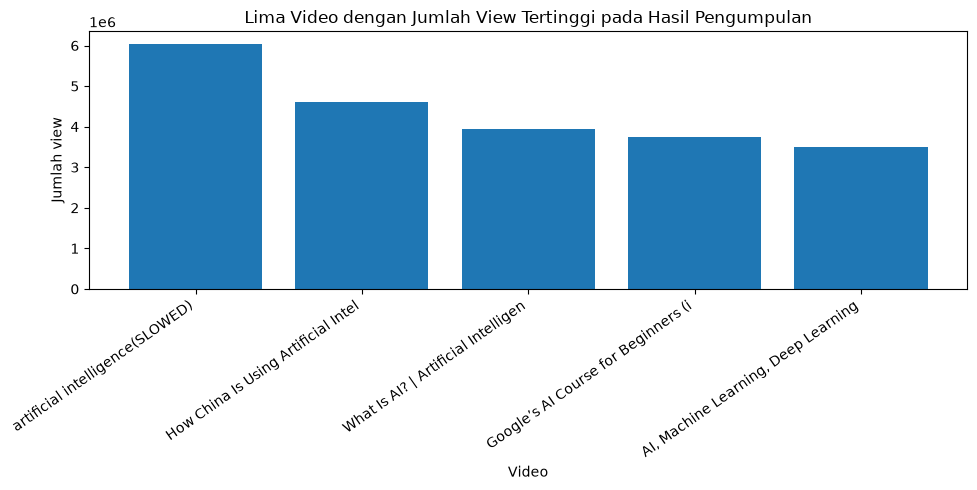

In [60]:
top_youtube_videos = df_youtube_videos.dropna(subset=["view_count"]).nlargest(5, "view_count")

plt.figure(figsize=(10, 5))
plt.bar(top_youtube_videos["title"].str.slice(0, 35), top_youtube_videos["view_count"])
plt.xticks(rotation=35, ha="right")
plt.xlabel("Video")
plt.ylabel("Jumlah view")
plt.title("Lima Video dengan Jumlah View Tertinggi pada Hasil Pengumpulan")
plt.tight_layout()
plt.show()

## 13. Melihat Daftar Region dan Bahasa yang Didukung


Beberapa endpoint menerima kode region atau bahasa. Daripada menebak nilai yang valid, kita dapat mengambil daftar resminya melalui `i18nRegions.list` dan `i18nLanguages.list`.

Bagian ini mengubah kedua response menjadi `DataFrame` agar kode dan nama region atau bahasa lebih mudah diperiksa sebelum digunakan pada request lain.

In [61]:
# Ambil daftar region dan bahasa yang didukung oleh YouTube Data API.
regions_response = youtube_get(
    "i18nRegions",
    {"part": "snippet"},
)

languages_response = youtube_get(
    "i18nLanguages",
    {"part": "snippet"},
)

# Ubah response region dan bahasa ke bentuk tabular.
df_youtube_regions = pd.json_normalize(
    regions_response.get("items", [])
)

df_youtube_languages = pd.json_normalize(
    languages_response.get("items", [])
)

# Tampilkan jumlah region dan bahasa yang tersedia.
print(f"Jumlah region tersedia: {len(df_youtube_regions)}")
print(f"Jumlah bahasa tersedia: {len(df_youtube_languages)}")

# Tampilkan beberapa baris pertama sebagai contoh.
display(df_youtube_regions.head())
display(df_youtube_languages.head())

Jumlah region tersedia: 111
Jumlah bahasa tersedia: 83


,kind,etag,id,snippet.gl,snippet.name
0,youtube#i18nRegion,RmvQrICcSKx5BZkuwuIam0hkr9o,AE,AE,United Arab Emirates
1,youtube#i18nRegion,lYa87JjqaXmfqWaf6vuQD3YSNo4,BH,BH,Bahrain
2,youtube#i18nRegion,sNy_f3n1a8hzh4cy6lk7Blq6MgU,DZ,DZ,Algeria
3,youtube#i18nRegion,epyyUiiXSMjhLjkCvWGK-3zDKpM,EG,EG,Egypt
4,youtube#i18nRegion,foRr-koDaxI_23FCQgzB6S9YdQw,IQ,IQ,Iraq


,kind,etag,id,snippet.hl,snippet.name
0,youtube#i18nLanguage,1OjwIvsEf9UstcR8l9SVbvsK8Qw,af,af,Afrikaans
1,youtube#i18nLanguage,ptN1RQzFShVdKYWSazyl6Givu1Q,am,am,Amharic
2,youtube#i18nLanguage,GOvkz2ITW6w0y-0cigEa0BiHOac,ar,ar,Arabic
3,youtube#i18nLanguage,qq6RBDRnnlL26sMbNlNgGRzeHUA,as,as,Assamese
4,youtube#i18nLanguage,uDg13IUyl-wwViQm18NMTW_ce0A,az,az,Azerbaijani


## 14. Mengambil Video Populer berdasarkan Region


Selain pencarian berbasis kata kunci, `videos.list` dapat digunakan untuk mengambil video yang sedang populer dengan `chart=mostPopular`. Parameter `regionCode` menentukan negara yang digunakan sebagai konteks popularitas.

Karena daftar video populer dapat berbeda antarregion, pilihan region perlu dicatat sebagai bagian dari konfigurasi pengumpulan data.

In [62]:
# Tentukan region yang digunakan untuk mengambil daftar video populer.
YOUTUBE_REGION_CODE = "ID"

# Ambil lima video yang masuk kategori mostPopular untuk region Indonesia.
most_popular_response = youtube_get(
    "videos",
    {
        "part": "snippet,statistics",
        "chart": "mostPopular",
        "regionCode": YOUTUBE_REGION_CODE,
        "maxResults": 5,
    },
)

# Ubah response menjadi bentuk tabular dan tampilkan hasilnya.
display(
    pd.json_normalize(
        most_popular_response.get("items", [])
    ).head()
)

,kind,etag,id,snippet.publishedAt,snippet.channelId,snippet.title,snippet.description,snippet.thumbnails.default.url,snippet.thumbnails.default.width,snippet.thumbnails.default.height,...,snippet.localized.title,snippet.localized.description,snippet.defaultAudioLanguage,statistics.viewCount,statistics.likeCount,statistics.favoriteCount,statistics.commentCount,snippet.thumbnails.qhd.url,snippet.thumbnails.qhd.width,snippet.thumbnails.qhd.height
0,youtube#video,9qUJQOPGzojj5U29OK-THvMPMvw,vAv7P8AEJPQ,2026-09-07T15:00:22Z,UC7Q3HUnJA3nvjZR2JeMn2Cw,Hearts2Hearts 하츠투하츠 'Moonride' MV Teaser,Hearts2Hearts 【Moonride】\n➫ 2026.09.09 6PM (KS...,https://i.ytimg.com/vi/vAv7P8AEJPQ/default.jpg,120,90,...,Hearts2Hearts 하츠투하츠 'Moonride' MV Teaser,Hearts2Hearts 【Moonride】\n➫ 2026.09.09 6PM (KS...,ko,646907,48456,0,2637,NaN,NaN,NaN
1,youtube#video,K1ZGEaYXHKpF2wNHU-hDhPzB0Fk,BwzcpZxkTYg,2026-09-08T03:11:06Z,UC0PDovAfG07_dcQvlVtblOg,TERIKAT JANJI TRAILER: SENA PANIK‼️ KO BISA KE...,Tonton video menarik lainnya dari sinetron TER...,https://i.ytimg.com/vi/BwzcpZxkTYg/default.jpg,120,90,...,TERIKAT JANJI TRAILER: SENA PANIK‼️ KO BISA KE...,Tonton video menarik lainnya dari sinetron TER...,id,93207,701,0,210,NaN,NaN,NaN
2,youtube#video,HxSyzX8eqcZVkSCz1WOB7a5nB4s,SoaOs25l384,2026-09-07T23:00:17Z,UCJ9v-fDARn2Vyl1TX9PfVyA,Yuta Mio Sembunyi Dari Hantu IBU BILANG PAKAI ...,🎮 Selamat datang di Dunia Budi Roblox!\nYuk ik...,https://i.ytimg.com/vi/SoaOs25l384/default.jpg,120,90,...,Yuta Mio Sembunyi Dari Hantu IBU BILANG PAKAI ...,🎮 Selamat datang di Dunia Budi Roblox!\nYuk ik...,id,301808,2549,0,120,NaN,NaN,NaN
3,youtube#video,v9dEXeFX5FAwXQULD7TNJqXKSD0,238X2xUGxRM,2026-09-07T21:00:25Z,UCx6wiW0udyr9PoAeBz3fdrg,Katy Perry - The One That Got Away (Lyrics),🎵Katy Perry - The One That Got Away (Lyrics)\n...,https://i.ytimg.com/vi/238X2xUGxRM/default.jpg,120,90,...,Katy Perry - The One That Got Away (Lyrics),🎵Katy Perry - The One That Got Away (Lyrics)\n...,en,168268,898,0,6,NaN,NaN,NaN
4,youtube#video,uVgpNjEdd0xlfBtelq4N5RzyY9s,mX_KYPLhUr0,2026-09-07T13:33:15Z,UCMui5CsNJjPdsaCDTeXrOvA,"TRAILER MERANGKAI KISAH INDAH HARI INI. NYATA,...",Assalamualaikum warahmatullahi wa barokatu hal...,https://i.ytimg.com/vi/mX_KYPLhUr0/default.jpg,120,90,...,"TRAILER MERANGKAI KISAH INDAH HARI INI. NYATA,...",Assalamualaikum warahmatullahi wa barokatu hal...,en,43741,202,0,100,https://i.ytimg.com/vi/mX_KYPLhUr0/qhddefault.jpg,2560.0,1440.0


## 15. Mencari Channel melalui Handle


Selain menggunakan `channelId`, channel juga dapat dicari melalui handle publik seperti `@GoogleDevelopers`. Parameter `forHandle` memudahkan pencarian ketika kita mengetahui handle tetapi belum memiliki ID channel.

- Channel name: lebih human-readable dan belum tentu unik.
- Handle channel: identifier publik yang lebih gampang dibaca/dicari manusia.
- Channel ID: identifier internal YouTube yang bentuknya string panjang.

Cell berikut meminta metadata channel berdasarkan handle dan menampilkan hasilnya jika ditemukan.

In [63]:
# Tentukan handle channel YouTube yang ingin dicari.
YOUTUBE_CHANNEL_HANDLE = "@GoogleDevelopers"

# Cari informasi channel berdasarkan handle menggunakan parameter forHandle.
channel_by_handle_response = youtube_get(
    "channels",
    {
        "part": "snippet",
        "forHandle": YOUTUBE_CHANNEL_HANDLE,
    },
)

channel_by_handle_items = channel_by_handle_response.get("items", [])

# Tampilkan informasi channel jika handle berhasil ditemukan.
if channel_by_handle_items:
    display(pd.json_normalize(channel_by_handle_items))

else:
    # Beri informasi jika handle tidak ditemukan oleh API.
    print(
        f"Handle {YOUTUBE_CHANNEL_HANDLE} tidak ditemukan. "
        "Gunakan handle lain yang valid."
    )

,kind,etag,id,snippet.title,snippet.description,snippet.customUrl,snippet.publishedAt,snippet.thumbnails.default.url,snippet.thumbnails.default.width,snippet.thumbnails.default.height,snippet.thumbnails.medium.url,snippet.thumbnails.medium.width,snippet.thumbnails.medium.height,snippet.thumbnails.high.url,snippet.thumbnails.high.width,snippet.thumbnails.high.height,snippet.localized.title,snippet.localized.description,snippet.country
0,youtube#channel,3SM4oJD_ZTR_hw-9FK6LZqA72Uw,UC_x5XG1OV2P6uZZ5FSM9Ttw,Google for Developers,Subscribe to join a community of creative deve...,@googledevelopers,2007-08-23T00:34:43Z,https://yt3.ggpht.com/Jrfy3VrP1QDikidneCoruk9M...,88,88,https://yt3.ggpht.com/Jrfy3VrP1QDikidneCoruk9M...,240,240,https://yt3.ggpht.com/Jrfy3VrP1QDikidneCoruk9M...,800,800,Google for Developers,Subscribe to join a community of creative deve...,US


## 16. Mengakses Playlist dan Upload Playlist Channel


YouTube menyediakan upload playlist khusus untuk setiap channel. Playlist ini berisi daftar video yang diunggah oleh channel tersebut. ID-nya dapat ditemukan pada `contentDetails.relatedPlaylists.uploads`.

Bagian berikut mengambil upload playlist dari salah satu channel hasil pengumpulan, lalu membandingkannya dengan daftar playlist biasa milik channel tersebut. Isi playlist kemudian dibaca melalui `playlistItems.list`.

In [64]:
# Pilih satu channel dari hasil sebelumnya sebagai contoh.
YOUTUBE_DEMO_CHANNEL_ID = df_youtube_channels.iloc[0]["channel_id"]

# Ambil contentDetails untuk mendapatkan ID uploads playlist milik channel.
channel_content_response = youtube_get(
    "channels",
    {
        "part": "snippet,contentDetails",
        "id": YOUTUBE_DEMO_CHANNEL_ID,
    },
)

channel_content_items = channel_content_response.get("items", [])

if not channel_content_items:
    raise RuntimeError(
        f"Channel {YOUTUBE_DEMO_CHANNEL_ID} tidak mengembalikan item."
    )

# Setiap channel memiliki uploads playlist yang berisi video yang diunggah channel tersebut.
uploads_playlist_id = (
    channel_content_items[0]
    ["contentDetails"]
    ["relatedPlaylists"]
    ["uploads"]
)

print("ID upload playlist:", uploads_playlist_id)


# Ambil maksimal lima playlist yang dimiliki channel.
playlist_response = youtube_get(
    "playlists",
    {
        "part": "snippet,contentDetails",
        "channelId": YOUTUBE_DEMO_CHANNEL_ID,
        "maxResults": 5,
    },
)

# Ambil maksimal lima video dari uploads playlist channel.
playlist_items_response = youtube_get(
    "playlistItems",
    {
        "part": "snippet,contentDetails",
        "playlistId": uploads_playlist_id,
        "maxResults": 5,
    },
)

# Tampilkan daftar playlist dan isi uploads playlist dalam bentuk tabular.
display(pd.json_normalize(playlist_response.get("items", [])).head())
display(pd.json_normalize(playlist_items_response.get("items", [])).head())

ID upload playlist: UUUYgCukQfUN2DImPYrBiV4g


,kind,etag,id,snippet.publishedAt,snippet.channelId,snippet.title,snippet.description,snippet.thumbnails.default.url,snippet.thumbnails.default.width,snippet.thumbnails.default.height,...,snippet.thumbnails.standard.url,snippet.thumbnails.standard.width,snippet.thumbnails.standard.height,snippet.thumbnails.maxres.url,snippet.thumbnails.maxres.width,snippet.thumbnails.maxres.height,snippet.channelTitle,snippet.localized.title,snippet.localized.description,contentDetails.itemCount
0,youtube#playlist,1p07cdY5AnZrcTb1vUxG9hImcFc,PLG5cepH-XErCWqAmLDLl8Re_leVCjAVJf,2025-04-01T11:33:24.699141Z,UCUYgCukQfUN2DImPYrBiV4g,Critical Thinking Course | Upgrade Otak dengan...,,https://i.ytimg.com/vi/9mLTtr9h81M/default.jpg,120,90,...,https://i.ytimg.com/vi/9mLTtr9h81M/sddefault.jpg,640,480,https://i.ytimg.com/vi/9mLTtr9h81M/maxresdefau...,1280,720,Fajrul Fx,Critical Thinking Course | Upgrade Otak dengan...,,6
1,youtube#playlist,Pb4dLKNT3ghSGWxUNN3jcqw-xjY,PLG5cepH-XErD97W7YgpoF2idYT-8i9h1U,2025-04-01T10:42:40.869568Z,UCUYgCukQfUN2DImPYrBiV4g,Critical Thinking Course,,https://i.ytimg.com/vi/9mLTtr9h81M/default.jpg,120,90,...,https://i.ytimg.com/vi/9mLTtr9h81M/sddefault.jpg,640,480,https://i.ytimg.com/vi/9mLTtr9h81M/maxresdefau...,1280,720,Fajrul Fx,Critical Thinking Course,,6
2,youtube#playlist,TF3te4c2kbNAnrQ9JvRDV4wlF5o,PLG5cepH-XErCwAkTtVsLdlN8QjVIFIk6W,2025-03-13T09:49:50.329232Z,UCUYgCukQfUN2DImPYrBiV4g,Sains Internet,,https://i.ytimg.com/vi/fl92C754MAc/default.jpg,120,90,...,https://i.ytimg.com/vi/fl92C754MAc/sddefault.jpg,640,480,https://i.ytimg.com/vi/fl92C754MAc/maxresdefau...,1280,720,Fajrul Fx,Sains Internet,,7
3,youtube#playlist,BBbmRkIEJBgHZcI7EVEEbPfC4f8,PLG5cepH-XErD1ZbWzYhRzKy0g9J-Vi6i6,2025-03-09T13:46:01.040572Z,UCUYgCukQfUN2DImPYrBiV4g,Genius Course | Cara Belajar Efektif dan Menja...,- Apakah kamu sering mengalami kesulitan dalam...,https://i.ytimg.com/vi/ID8sBtuoM6s/default.jpg,120,90,...,https://i.ytimg.com/vi/ID8sBtuoM6s/sddefault.jpg,640,480,https://i.ytimg.com/vi/ID8sBtuoM6s/maxresdefau...,1280,720,Fajrul Fx,Genius Course | Cara Belajar Efektif dan Menja...,- Apakah kamu sering mengalami kesulitan dalam...,9
4,youtube#playlist,sH13p7JQEJw2mxzDGt8_86EI5B4,PLG5cepH-XErAQV-rCTiUfmB4oBERn9Vy3,2024-09-30T10:52:45.196549Z,UCUYgCukQfUN2DImPYrBiV4g,Insiden Sains,,https://i.ytimg.com/vi/sc8lPAtwNbk/default.jpg,120,90,...,https://i.ytimg.com/vi/sc8lPAtwNbk/sddefault.jpg,640,480,https://i.ytimg.com/vi/sc8lPAtwNbk/maxresdefau...,1280,720,Fajrul Fx,Insiden Sains,,16


,kind,etag,id,snippet.publishedAt,snippet.channelId,snippet.title,snippet.description,snippet.thumbnails.default.url,snippet.thumbnails.default.width,snippet.thumbnails.default.height,...,snippet.thumbnails.maxres.height,snippet.channelTitle,snippet.playlistId,snippet.position,snippet.resourceId.kind,snippet.resourceId.videoId,snippet.videoOwnerChannelTitle,snippet.videoOwnerChannelId,contentDetails.videoId,contentDetails.videoPublishedAt
0,youtube#playlistItem,byNrLZOLCHxQFuMHH50WmZd_bRQ,VVVVWWdDdWtRZlVOMkRJbVBZckJpVjRnLnVObkc2ckJiREpF,2026-09-08T13:14:01Z,UCUYgCukQfUN2DImPYrBiV4g,Apa yang sebenarnya terjadi pada Gunung Anak K...,Buku Membaca Semesta: Fisika di Sekitar Kita b...,https://i.ytimg.com/vi/uNnG6rBbDJE/default.jpg,120,90,...,720,Fajrul Fx,UUUYgCukQfUN2DImPYrBiV4g,0,youtube#video,uNnG6rBbDJE,Fajrul Fx,UCUYgCukQfUN2DImPYrBiV4g,uNnG6rBbDJE,2026-09-08T13:14:01Z
1,youtube#playlistItem,_Wz8ReSDyGZcr9gwDm7Tp951K1Y,VVVVWWdDdWtRZlVOMkRJbVBZckJpVjRnLjMyNUVfTnJaVUlB,2026-09-04T11:23:15Z,UCUYgCukQfUN2DImPYrBiV4g,Misteri Ledakan Meteor Terkuat dan Teraneh di ...,Cobain Dreamina Seedance 2.5 sekarang : https:...,https://i.ytimg.com/vi/325E_NrZUIA/default.jpg,120,90,...,720,Fajrul Fx,UUUYgCukQfUN2DImPYrBiV4g,1,youtube#video,325E_NrZUIA,Fajrul Fx,UCUYgCukQfUN2DImPYrBiV4g,325E_NrZUIA,2026-09-04T11:23:15Z
2,youtube#playlistItem,bgev33j_6B-g9qhL7k0iD2sdUls,VVVVWWdDdWtRZlVOMkRJbVBZckJpVjRnLlFWMmF3d3NFRWc4,2026-08-31T09:38:27Z,UCUYgCukQfUN2DImPYrBiV4g,sepertinya orang2 ini selalu bolos pelajaran f...,Buku Membaca Semesta: Fisika di Sekitar Kita b...,https://i.ytimg.com/vi/QV2awwsEEg8/default.jpg,120,90,...,720,Fajrul Fx,UUUYgCukQfUN2DImPYrBiV4g,2,youtube#video,QV2awwsEEg8,Fajrul Fx,UCUYgCukQfUN2DImPYrBiV4g,QV2awwsEEg8,2026-08-31T09:38:27Z
3,youtube#playlistItem,zjEN4eiMech2WexVy433msXtd8w,VVVVWWdDdWtRZlVOMkRJbVBZckJpVjRnLkxfNXZ4UXdoOGtF,2026-08-26T09:00:22Z,UCUYgCukQfUN2DImPYrBiV4g,Orang ini tidak sengaja meracuni 100.000.000+ ...,Buku Membaca Semesta: Fisika di Sekitar Kita b...,https://i.ytimg.com/vi/L_5vxQwh8kE/default.jpg,120,90,...,720,Fajrul Fx,UUUYgCukQfUN2DImPYrBiV4g,3,youtube#video,L_5vxQwh8kE,Fajrul Fx,UCUYgCukQfUN2DImPYrBiV4g,L_5vxQwh8kE,2026-08-26T09:00:22Z
4,youtube#playlistItem,JM_CCiUSYAACRv1cK5D9k2G0-ks,VVVVWWdDdWtRZlVOMkRJbVBZckJpVjRnLjZEeXRVeW9ndGhZ,2026-08-20T09:53:57Z,UCUYgCukQfUN2DImPYrBiV4g,Sejarah Lengkap Bagaimana Listrik Ditemukan,Buku Membaca Semesta: Fisika di Sekitar Kita b...,https://i.ytimg.com/vi/6DytUyogthY/default.jpg,120,90,...,720,Fajrul Fx,UUUYgCukQfUN2DImPYrBiV4g,4,youtube#video,6DytUyogthY,Fajrul Fx,UCUYgCukQfUN2DImPYrBiV4g,6DytUyogthY,2026-08-20T09:53:57Z


## 17. Membatasi Response dengan Parameter `fields`


Secara default, API dapat mengembalikan lebih banyak field daripada yang benar-benar dibutuhkan. Parameter `fields` memungkinkan kita membatasi struktur response hanya ke field tertentu.

Bagian berikut membandingkan ukuran response penuh dengan response yang dibatasi menggunakan `fields`. Pengurangan ukuran response dapat menghemat transfer data, tetapi tidak mengubah biaya kuota endpoint.

In [65]:
# Pilih satu video dari hasil sebelumnya sebagai contoh.
YOUTUBE_SAMPLE_VIDEO_ID = df_youtube_videos.iloc[0]["video_id"]

# Ambil response snippet secara lengkap tanpa membatasi field yang dikembalikan.
full_response = youtube_get(
    "videos",
    {
        "part": "snippet",
        "id": YOUTUBE_SAMPLE_VIDEO_ID,
    },
)

# Gunakan fields untuk membatasi response hanya ke data yang dibutuhkan.
partial_response = youtube_get(
    "videos",
    {
        "part": "snippet",
        "id": YOUTUBE_SAMPLE_VIDEO_ID,
        "fields": "items(id,snippet(title,publishedAt))",
    },
)

# Bandingkan ukuran response untuk melihat efek penggunaan fields.
print(
    "Ukuran response tanpa fields:",
    len(json.dumps(full_response)),
    "karakter",
)

print(
    "Ukuran response dengan fields:",
    len(json.dumps(partial_response)),
    "karakter",
)

# Tampilkan response yang telah dibatasi menggunakan fields.
display(partial_response)

Ukuran response tanpa fields: 6184 karakter
Ukuran response dengan fields: 175 karakter


{'items': [{'id': 'btpRfPC3Yhw',
   'snippet': {'publishedAt': '2026-09-07T17:20:06Z',
    'title': "Artificial Intelligence | AI's Alien Mind: Can Humans Still Stay In Control?"}}]}

## 18. Menggunakan ETag untuk Conditional Request


Response YouTube dapat menyertakan `etag`, yaitu identifier untuk versi representasi data tertentu. Nilai ini dapat dikirim kembali melalui header `If-None-Match`. Jika representasi data belum berubah, server dapat mengembalikan status `304 Not Modified` tanpa mengirim ulang body response.

Agar perbandingan valid, request pertama dan conditional request harus menggunakan parameter yang sama. Perubahan parameter, termasuk penggunaan `fields`, dapat menghasilkan representasi dan ETag yang berbeda.

In [66]:
# Tentukan parameter untuk mengambil satu video sebagai demonstrasi ETag.
etag_request_parameters = {
    "part": "snippet",
    "id": YOUTUBE_SAMPLE_VIDEO_ID,
}

# Lakukan request pertama untuk mendapatkan data beserta ETag-nya.
first_response = requests.get(
    f"{YOUTUBE_API_BASE_URL}/videos",
    params={
        **etag_request_parameters,
        "key": YT_API_KEY,
    },
    timeout=REQUEST_TIMEOUT_SECONDS,
)

first_response.raise_for_status()

# Ambil ETag yang merepresentasikan versi response saat ini.
etag = first_response.json().get("etag")

# Kirim request yang sama dengan ETag sebelumnya melalui header If-None-Match.
# Jika data belum berubah, server dapat merespons dengan 304 Not Modified.
conditional_response = requests.get(
    f"{YOUTUBE_API_BASE_URL}/videos",
    params={
        **etag_request_parameters,
        "key": YT_API_KEY,
    },
    headers={"If-None-Match": etag},
    timeout=REQUEST_TIMEOUT_SECONDS,
)

# Bandingkan status HTTP dan ukuran body dari kedua request.
print(
    "Status request pertama:",
    first_response.status_code,
    f"({len(first_response.content)} byte pada body)",
)

print(
    "Status conditional request:",
    conditional_response.status_code,
    f"({len(conditional_response.content)} byte pada body)",
)

Status request pertama: 200 (6987 byte pada body)
Status conditional request: 304 (0 byte pada body)


## 19. Menggunakan Kompresi Gzip


Response HTTP dapat dikompresi dengan gzip untuk mengurangi ukuran data yang dikirim melalui jaringan. Pada contoh ini, klien meminta gzip melalui header `Accept-Encoding` dan mencantumkan `gzip` pada `User-Agent`.

Library `requests` akan melakukan decompression secara otomatis. Karena itu, kita membandingkan informasi pada header dengan ukuran content setelah di-decode untuk memahami apa yang terjadi selama transfer.

In [67]:
# Request response dalam format gzip untuk mengurangi ukuran data yang ditransfer.
gzip_response = requests.get(
    f"{YOUTUBE_API_BASE_URL}/videos",
    params={
        **etag_request_parameters,
        "key": YT_API_KEY,
    },
    headers={
        "Accept-Encoding": "gzip",
        "User-Agent": "anmedsos-tutorial1 (gzip)",
    },
    timeout=REQUEST_TIMEOUT_SECONDS,
)

gzip_response.raise_for_status()

# Periksa apakah server mengirim response menggunakan kompresi gzip.
print(
    "Content-Encoding:",
    gzip_response.headers.get("Content-Encoding"),
)

# Content-Length menunjukkan ukuran response terkompresi jika header tersedia.
print(
    "Ukuran response terkompresi menurut header:",
    gzip_response.headers.get("Content-Length"),
    "byte",
)

# requests secara otomatis melakukan decompression sebelum content diakses.
print(
    "Ukuran content setelah di-decode:",
    len(gzip_response.content),
    "byte",
)

Content-Encoding: gzip
Ukuran response terkompresi menurut header: None byte
Ukuran content setelah di-decode: 6987 byte
